# Image restoration with an encoder-decoder

Damage clean images on purpose and train a network to undo the damage: the damaged
image is the input, the original is the target. No labels are needed, so any image
collection is training data.

The same model works for several kinds of damage:

- `"noise"` — Gaussian noise (denoising)
- `"mask"` — a missing 8×8 square (inpainting)
- `"lowres"` — half resolution, scaled back up (super-resolution)

Two models are compared: a plain **autoencoder**, where everything must pass through a
small bottleneck, and a **U-Net**, where skip connections carry details past it.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow"   # "jax" and "torch" also work

import time
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

# On a Mac the Metal GPU trains this small model several times slower than the CPU.
import platform
if keras.config.backend() == "tensorflow" and platform.system() == "Darwin":
    import tensorflow as tf
    tf.config.set_visible_devices([], "GPU")

keras.utils.set_random_seed(0)
print(keras.__version__, keras.config.backend())

3.15.1 tensorflow


## Data

CIFAR-10 images, 32×32×3, scaled to [0, 1]. The labels are not used.

In [2]:
(x_train, _), (x_test, _) = keras.datasets.cifar10.load_data()
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

x_val, x_train = x_train[:5000], x_train[5000:]
print(x_train.shape, x_val.shape, x_test.shape)

(45000, 32, 32, 3) (5000, 32, 32, 3) (10000, 32, 32, 3)


## Damage

Change `kind` and run the notebook again.

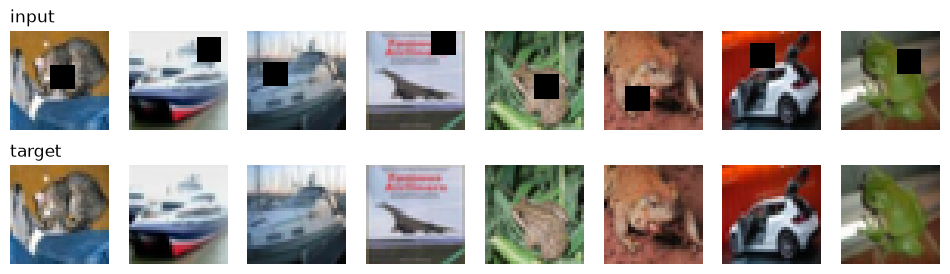

In [4]:
kind = "mask"    # "noise", "mask" or "lowres"
rng = np.random.default_rng(0)

def damage(x, kind):
    if kind == "noise":
        return np.clip(x + rng.normal(0, 0.1, x.shape), 0, 1).astype("float32")
    if kind == "mask":
        x = x.copy()
        for img in x:
            i, j = rng.integers(0, 32 - 8, size=2)
            img[i:i + 8, j:j + 8] = 0
        return x
    if kind == "lowres":
        n = len(x)
        small = x.reshape(n, 16, 2, 16, 2, 3).mean(axis=(2, 4))   # 2×2 average
        return small.repeat(2, axis=1).repeat(2, axis=2)          # back to 32×32
    raise ValueError(kind)

d_train, d_val, d_test = damage(x_train, kind), damage(x_val, kind), damage(x_test, kind)

fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for k in range(8):
    ax[0, k].imshow(d_test[k]); ax[1, k].imshow(x_test[k])
    ax[0, k].axis("off"); ax[1, k].axis("off")
ax[0, 0].set_title("input", loc="left"); ax[1, 0].set_title("target", loc="left")
plt.show()

## Measure: PSNR

Peak signal-to-noise ratio for images in [0, 1]:

$$\mathrm{PSNR} = 10 \log_{10} \frac{1}{\mathrm{MSE}} \ \text{dB}.$$

MSE is the mean over all test images. Larger is better; +3 dB means half the MSE. The baseline is the damaged image itself:
a model is useful only if it beats doing nothing.

In [5]:
def psnr(a, b):
    mse = np.mean((a - b) ** 2)      # over all images and pixels
    return 10 * np.log10(1 / mse)

print(f"baseline (damaged input): {psnr(d_test, x_test):.2f} dB")

baseline (damaged input): 17.54 dB


## Models

The same encoder and decoder; `skip=True` adds the U-Net skip connections.

```
32×32×32 ──────────────────────────────── (skip) ──→ 32×32×32 → 32×32×3
   ↓ pool                                                ↑ upsample
   16×16×64 ─────────────── (skip) ──→ 16×16×64
      ↓ pool                              ↑ upsample
      8×8×16  bottleneck: 1024 numbers, a third of the 3072 in the image
```

In [6]:
def conv(x, filters):
    return layers.Conv2D(filters, 3, padding="same", activation="relu")(x)

def build(skip):
    inputs = keras.Input(shape=(32, 32, 3))
    e1 = conv(inputs, 32)                              # 32×32×32
    e2 = conv(layers.MaxPooling2D()(e1), 64)           # 16×16×64
    b = conv(layers.MaxPooling2D()(e2), 16)            # 8×8×16 bottleneck

    u2 = layers.UpSampling2D()(b)                      # 16×16
    if skip:
        u2 = layers.Concatenate()([u2, e2])
    d2 = conv(u2, 64)

    u1 = layers.UpSampling2D()(d2)                     # 32×32
    if skip:
        u1 = layers.Concatenate()([u1, e1])
    d1 = conv(u1, 32)

    outputs = layers.Conv2D(3, 1, activation="sigmoid")(d1)
    return keras.Model(inputs, outputs, name="unet" if skip else "autoencoder")

models = {"autoencoder": build(skip=False), "U-Net": build(skip=True)}
for name, m in models.items():
    print(f"{name:12s} {m.count_params():,} parameters")

autoencoder  56,467 parameters
U-Net        102,547 parameters


## Training

Loss: mean squared error between the output and the original image.

autoencoder  153 s, val_loss 0.00499
U-Net        227 s, val_loss 0.00153


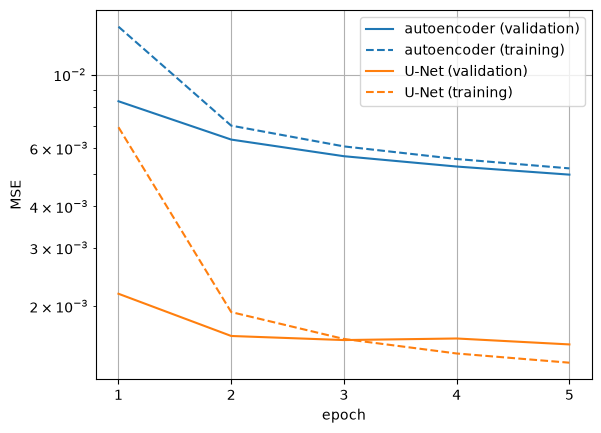

In [7]:
epochs = 5
histories = {}
for name, m in models.items():
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")
    t0 = time.time()
    histories[name] = m.fit(d_train, x_train, validation_data=(d_val, x_val),
                            epochs=epochs, batch_size=128, verbose=0)
    print(f"{name:12s} {time.time() - t0:.0f} s, val_loss {histories[name].history['val_loss'][-1]:.5f}")

for (name, h), color in zip(histories.items(), ["C0", "C1"]):
    epoch = np.arange(1, epochs + 1)
    plt.plot(epoch, h.history["val_loss"], color, label=f"{name} (validation)")
    plt.plot(epoch, h.history["loss"], color, linestyle="--", label=f"{name} (training)")
plt.xticks(np.arange(1, epochs + 1))
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.yscale("log"); plt.grid(); plt.legend()
plt.show()

## Results on test data

baseline     17.54 dB
autoencoder  23.01 dB
U-Net        28.13 dB


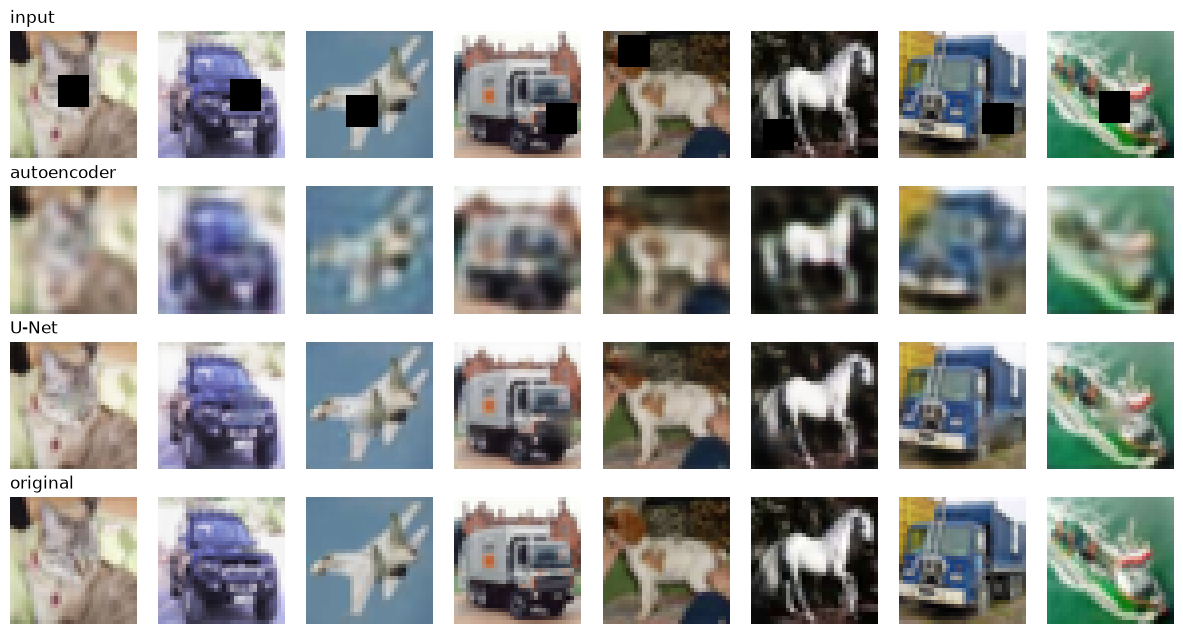

In [8]:
outputs = {name: m.predict(d_test, batch_size=256, verbose=0) for name, m in models.items()}

print(f"{'baseline':12s} {psnr(d_test, x_test):.2f} dB")
for name, out in outputs.items():
    print(f"{name:12s} {psnr(out, x_test):.2f} dB")

rows = [("input", d_test)] + list(outputs.items()) + [("original", x_test)]
fig, ax = plt.subplots(len(rows), 8, figsize=(12, 1.6 * len(rows)))
for r, (name, imgs) in enumerate(rows):
    for k in range(8):
        ax[r, k].imshow(imgs[k + 8]); ax[r, k].axis("off")
    ax[r, 0].set_title(name, loc="left")
plt.tight_layout()
plt.show()

## Things to try

- Other kinds of damage: `kind = "mask"` or `"lowres"`, stronger noise, a larger hole.
- Colourisation: a greyscale input (one channel), a colour target.
- Loss: `"mae"` instead of `"mse"`. Which gives sharper images, and why?
- A larger or smaller bottleneck, more levels, more filters.
- Your own photos: cut them into small patches, or use a larger input size.